# Does the best tested configuration reproduce the PV signal?

**50 fresh independent Gaussian initial conditions**, seeds 1000–1049, with displacement strength **$A=16\ h^{-1}\mathrm{Mpc}$**. The box is $L=1000\ h^{-1}\mathrm{Mpc}$, the field mesh is $256^3$, and the particle lattice is $32^3$.

The amplitude, toy spectrum and tetrahedron selection are fixed from the earlier studies. Each realization has three matched catalogues: $\epsilon=-1$ (negative helicity), $0$ (equal expected helical powers), and $+1$ (positive helicity). Both the Gaussian density and helical fields vary between realizations; the three cases share those draws within a realization. The earlier amplitude-scan ICs are excluded.
Sections 1–3 report the original frozen $r$ selection. Section 4 compares the fiducial $Q$ cut across five helicities, including 50 additional independent ICs for $\epsilon=\pm0.5$.


In [1]:
from pathlib import Path
import html,json,sys
import numpy as np
from IPython.display import display,Markdown,HTML
RUN=Path('/srv/beegfs/scratch/users/h/hes/projects/cosmicPV/20261122_mesh_ic_L1000_N256_A16_confirmation_50')
OUT=Path('/srv/beegfs/scratch/users/h/hes/projects/cosmicPV/field_PVdisp_B')
sys.path.insert(0,str(RUN/"code/src"))
from parity_study.storage import digest
from parity_study.best_confirmation import distribution_figure
protocol=json.loads((OUT/"protocol.json").read_text())
report=json.loads((OUT/"analysis.json").read_text())
assert report["complete"] and report["protocol_sha256"]==digest(OUT/"protocol.json")
assert report["independent_ic_audit"]["passed"]
with np.load(OUT/"confirmation.npz") as z:
    signals=z["signals"]
    paired=z["paired"]
    seeds=z["seeds"]
assert seeds.tolist()==protocol["seeds"]
primary_index=next(i for i,c in enumerate(protocol["cuts"]) if c["id"]==protocol["primary_selection"])
display(Markdown(f"**Complete:** {len(seeds)} ICs × 3 helicities = **{3*len(seeds)} catalogue signals**, "
                 f"plus {len(seeds)} ZA-only controls. Distinct fields and exact matched particle maps verified."))
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi":110,"font.size":11})

def show_table(rows, columns):
    """Display a compact table; columns are (dictionary key, displayed heading)."""
    if not rows:
        display(Markdown("No measurements available for this section."))
        return
    def fmt(value):
        if value is None:
            return "—"
        if isinstance(value, (float, np.floating)):
            return f"{value:.5g}"
        return str(value)
    heading = "".join(f"<th>{html.escape(title)}</th>" for _, title in columns)
    body = "".join("<tr>" + "".join(
        f"<td>{html.escape(fmt(row.get(key)))}</td>" for key, _ in columns) + "</tr>"
        for row in rows)
    display(HTML("<div style='overflow-x:auto'><table><thead><tr>" + heading +
                 "</tr></thead><tbody>" + body + "</tbody></table></div>"))

**Complete:** 50 ICs × 3 helicities = **150 catalogue signals**, plus 50 ZA-only controls. Distinct fields and exact matched particle maps verified.

## 1. What is the catalogue signal?

Order the tetrahedron vertices by their sums of squared distances to the other vertices. From the first vertex, take the three edge vectors in that order:
$$\widehat\chi_t=\frac{\mathbf v_1\cdot(\mathbf v_2\times\mathbf v_3)}{|\mathbf v_1||\mathbf v_2||\mathbf v_3|}.$$
Keep both chirality signs with the fixed shape selection
$$B:\quad 0.6905111410000623\leq\frac{\ell_{\min}}{\ell_{\max}}<0.7567675934849439,$$
where the lengths are those of the **three edges from the reference vertex**.

For realization $s$, the **catalogue signal** is $S_{s,B}(\epsilon)=\mathrm{mean}_{t\in B}\widehat\chi_t$. Each histogram below contains 50 catalogue signals, one per IC; its horizontal axis is $S_{s,B}$.

## 2. Catalogue-signal distributions: three helicities

Shaded histograms show measured probability densities, each integrating to one. The curves are Gaussian approximations $\mathcal N(\mu,\sigma_S^2)$ fitted using the **sample mean** $\mu$ and **sample standard deviation** $\sigma_S$ across catalogues. Gaussianity is not assumed to be exact.

The curve width $\sigma_S$ describes catalogue-to-catalogue scatter. The **standard error of the mean**, $\mathrm{SEM}=\sigma_S/\sqrt{50}$, describes uncertainty in the ensemble mean and is smaller than the curve width.

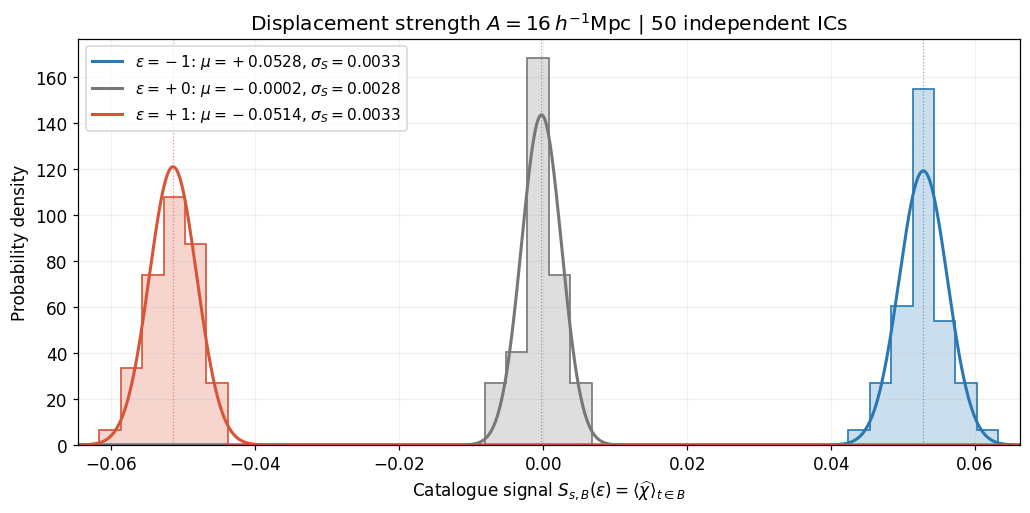

ε,Catalogues,Mean μ,Scatter σS,SEM
-1,50,0.05279,0.0033483,0.00047353
0,50,-0.00024445,0.0027799,0.00039314
1,50,-0.051421,0.0032984,0.00046647


In [2]:
fig=distribution_figure(report,signals,primary_index)
(OUT/"figures").mkdir(parents=True,exist_ok=True)
for ext in ("png","pdf"):
    fig.savefig(OUT/"figures"/f"catalogue_signal_distributions.{ext}",dpi=180,bbox_inches="tight")
plt.show()
plt.close(fig)
rows=[r for r in report["distributions"] if r["selection"]==report["primary_selection"]]
show_table(rows,[("epsilon","ε"),("n","Catalogues"),("mean","Mean μ"),
                 ("sd","Scatter σS"),("sem","SEM")])

## 3. Is the helicity difference reproduced?

For each matched realization, define $D_{s,B}=S_{s,B}(+1)-S_{s,B}(-1)$. Its mean $\overline D_B$ measures the helicity separation. Negative values mean that positive-helicity catalogues have the lower chirality signal.

The primary test is a two-sided paired Student t test at $p<0.05$, requiring the negative sign found previously. Its SEM uses the scatter of the **50 matched differences**, including their correlation. A, the cut, and the sample size were frozen before generation.

In [3]:
p=report["primary"]
show_table([p],[("n","Matched ICs"),("mean","Mean D̄B"),("sem","SEM"),
                ("ci95_low","95% lower"),("ci95_high","95% upper"),("p_two_sided","Two-sided p")])
if report["primary_confirmed"]:
    display(Markdown(f"**The catalogue PV response is reproduced on 50 fresh ICs:** "
        f"$\\overline D_B={p['mean']:.6f}\\pm{p['sem']:.6f}$ (one SEM)."))
else:
    display(Markdown("**This sample does not establish the previously observed signed response.**"))
control=next(r for r in report["controls"] if r["selection"]==report["primary_selection"])["epsilon0"]
display(Markdown(f"**Equal-power control (ε=0):** mean signal {control['mean']:+.6f} ± {control['sem']:.6f} SEM; "
                 f"95% interval [{control['ci95_low']:+.6f}, {control['ci95_high']:+.6f}]."))
baseline=next(r for r in report["summaries"] if r["selection"]=="all")
display(Markdown(f"**All-tetrahedron comparison:** mean matched difference {baseline['mean']:+.6f} "
                 f"± {baseline['sem']:.6f} SEM (descriptive)."))

Matched ICs,Mean D̄B,SEM,95% lower,95% upper,Two-sided p
50,-0.10421,0.00058986,-0.1054,-0.10303,2.1732e-70


**The catalogue PV response is reproduced on 50 fresh ICs:** $\overline D_B=-0.104211\pm0.000590$ (one SEM).

**Equal-power control (ε=0):** mean signal -0.000244 ± 0.000393 SEM; 95% interval [-0.001034, +0.000546].

**All-tetrahedron comparison:** mean matched difference -0.031920 ± 0.000315 SEM (descriptive).

This verifies the catalogue response at the chosen configuration. Establishing a physical amplitude or a resolution-independent optimum requires separate tests.

[Protocol](saved/field_PVdisp_B/protocol.json) · [Catalogue signals](saved/field_PVdisp_B/confirmation_catalogues.csv) · [Gaussian parameters](saved/field_PVdisp_B/distribution_summary.csv) · [Saved arrays](saved/field_PVdisp_B/confirmation.npz) · [Figures](saved/field_PVdisp_B/figures/)

## 4. Fiducial $Q$ selection: catalogue-signal distributions

Use $B_Q:0.4\le Q<0.8$, where $Q=12(3V)^{2/3}/\sum_{i<j}\ell_{ij}^{2}$ uses the tetrahedron volume and all six edges. This selection is applied on its own, without the $r$ cut.

Each histogram contains **50 catalogue signals**, $S_{s,B_Q}(\epsilon)=\mathrm{mean}_{t\in B_Q}\widehat\chi_t$, at 32,768 particles and $A=16\ h^{-1}\mathrm{Mpc}$. Gaussian curves use the catalogue scatter $\sigma_S$ defined in Section 2.

- $\epsilon=-1,0,+1$: original IC seeds **1000–1049**; the $Q$ cut was chosen after inspecting this sample.
- $\epsilon=-0.5,+0.5$: **50 new ICs, seeds 1050–1099**, with $A$ and the $Q$ cut fixed before generation. Each pair shares its Gaussian density, ZA displacement and helical draws. These cases split the expected helical power 25:75 and 75:25 between the positive and negative components.

The two seed groups are independent; matched differences below pair helicities only within their own group.


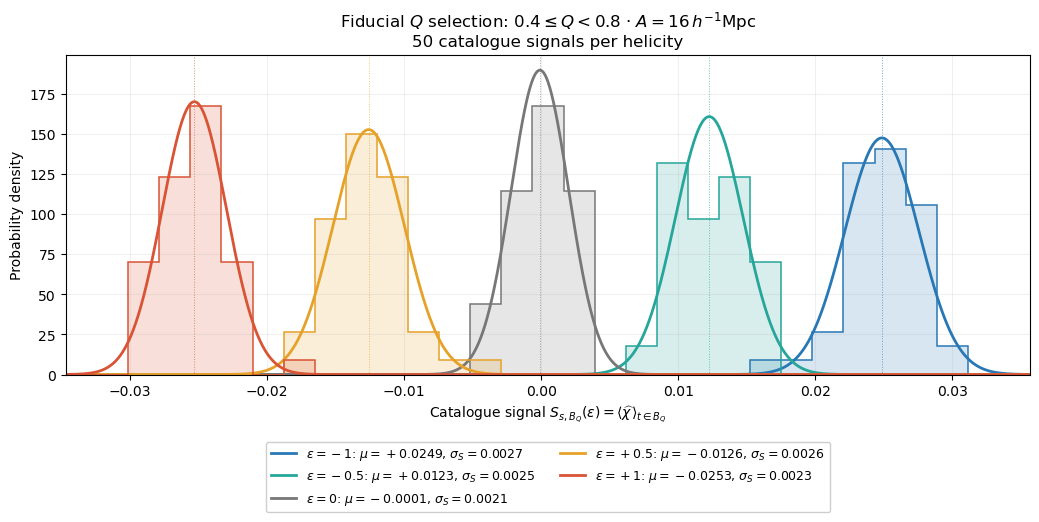

| ε | Catalogues | IC seeds | Mean μ | Scatter σS | SEM |
|---:|---:|---|---:|---:|---:|
| -1 | 50 | 1000–1049 | +0.024868 | 0.002703 | 0.000382 |
| -0.5 | 50 | 1050–1099 | +0.012269 | 0.002480 | 0.000351 |
| +0 | 50 | 1000–1049 | -0.000093 | 0.002101 | 0.000297 |
| +0.5 | 50 | 1050–1099 | -0.012594 | 0.002612 | 0.000369 |
| +1 | 50 | 1000–1049 | -0.025315 | 0.002344 | 0.000332 |

**Matched difference:** $D_{s,e}=S_{s,B_Q}(+e)-S_{s,B_Q}(-e)$. SEM uses the scatter of matched differences within each ensemble.

| e | Matched ICs | Mean D ± SEM |
|---:|---:|---:|
| 0.5 | 50 | -0.024863 ± 0.000471 |
| 1 | 50 | -0.050184 ± 0.000552 |

In [4]:
from pathlib import Path
import importlib.util
from IPython.display import display, Markdown
%matplotlib inline
import matplotlib.pyplot as plt
Q_HALF = Path('/srv/beegfs/scratch/users/h/hes/projects/cosmicPV/20261123_mesh_ic_L1000_N256_A16_epshalf_50/report')
spec = importlib.util.spec_from_file_location('pv_five_helicities', Q_HALF/'code/helicity_half_notebook.py')
five_helicities = importlib.util.module_from_spec(spec)
spec.loader.exec_module(five_helicities)
fig = five_helicities.figure(Q_HALF)
display(fig)
plt.close(fig)
display(Markdown(five_helicities.table_markdown(Q_HALF)))


[Catalogue signals](saved/20261123_mesh_ic_L1000_N256_A16_epshalf_50/report/catalogue_signals.csv) · [Gaussian parameters](saved/20261123_mesh_ic_L1000_N256_A16_epshalf_50/report/distribution_summary.csv) · [Matched differences](saved/20261123_mesh_ic_L1000_N256_A16_epshalf_50/report/paired_summary.csv) · [Figures](saved/20261123_mesh_ic_L1000_N256_A16_epshalf_50/report/figures/) · [New-run protocol](saved/20261123_mesh_ic_L1000_N256_A16_epshalf_50/protocol.json) · [Validation](saved/20261123_mesh_ic_L1000_N256_A16_epshalf_50/validation/ensemble.json)